# Mie calculation for droplets in GFAS opening angles
Here, theoretical scattering cross sections for the GFAS are being calculated for different refractive indices

author: Lea Haberstock, Stockholm University, Department of Environmental Science, Atmospheric Unit \
developed toether with: Julie Legrand, Darrel Baumgardner and Paul Zieger
for documentation of the Mie calculations see [PyMieScatt](https://pymiescatt.readthedocs.io/en/latest/)

contact: lea.haberstock@aces.su.se \
used in publication: Haberstock et al. 2026 (submitted to AMT) 


Last modified June 01/07/2026

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import PyMieScatt  as pms
import pandas as pd
import matplotlib as mpl
import matplotlib.gridspec as gridspec

### Forward and back scattering cross sections GFAS 
wavelength = 660 nm \
opening angles
- backward 168-176.5 deg
- forward 3.8-20 deg

In [9]:
def mie_calculation(diameters, m=1.33):
     '''
     Process the Mie Calculations for a defined list of diameters and a range of diameters

     parameters:
     diameters : 1D-array    List of diameters
     m : float or complex    Refractive index
     output: scattering cross sections for 
        sigma_fw: forward scattering
        sigma_S: perpendicularly polarized backward scattering
        sigma_P: parallel polarized backward scattering
        sigma_x: measurable parallel polarized backward scattering
        sigma_y: measurable perpendicularly polarized backward scattering
     '''

     n=len(diameters)
     ang_bw = np.linspace(168, 176.5, 30) # backscattering opening angles
     ang_fw = np.linspace(3.8, 20, 30)  # forward scattering opening angles

     sigma_fw=np.zeros(n)
     sigma_S=np.zeros(n)
     sigma_P=np.zeros(n)
     sigma_J=np.zeros(n)
     for i,di in enumerate(diameters):
         x = di * np.pi / 660  # size parameter, unities [nm]/[nm]
         theta_fw, SL1, SR1, _ = pms.ScatteringFunction(m=m, wavelength=660, diameter=di, nMedium=1.0,  minAngle=ang_fw[0], maxAngle=ang_fw[-1], angularResolution= (ang_fw[-1]-ang_fw[0])/30 )
         theta_bw, SL, SR, _ = pms.ScatteringFunction(m=m, wavelength=660, diameter=di, nMedium=1.0,  minAngle=ang_bw[0], maxAngle=ang_bw[-1], angularResolution= (ang_bw[-1]-ang_bw[0])/30 )
         sc_tot =x ** (-2) * np.trapz((SL1+SR1) * np.sin(theta_fw), theta_fw)
         sc_L =x ** (-2) * np.trapz((SL) * np.sin(theta_bw), theta_bw)
         sc_R =x ** (-2) * np.trapz((SR) * np.sin(theta_bw), theta_bw)
         sigma_fw[i]=1e4*sc_tot*0.25 * np.pi * (di * 1e-9) ** 2 #di converted to meters, sigma converted to cm^2
         sigma_P[i]=1e4*sc_R*0.25 * np.pi * (di * 1e-9) ** 2 #di converted to meters, sigma converted to cm^2
         sigma_S[i]=1e4*sc_L*0.25 * np.pi * (di * 1e-9) ** 2 #di converted to meters, sigma converted to cm^2

         S1,S2=np.zeros(30, dtype=complex), np.zeros(30, dtype=complex)
         theta= ang_bw*np.pi/180 # into rad
         for j in range(30):
             S1[j],S2[j]=pms.MieS1S2(m, x, np.cos(theta[j]))
         sigma_J[i]= x**(-2)/4 *1e4 *np.pi * (di * 1e-9)**2 * np.trapz(np.real(S1 * np.conjugate(S2))* np.sin(theta), theta)

     sigma_x=.75*(sigma_S+sigma_P)-.5*sigma_J
     sigma_y=.25*(sigma_S+sigma_P)+.5*sigma_J

     return sigma_fw, sigma_S, sigma_P, sigma_x, sigma_y

### real part

In [34]:
## tryout the new code from Julie
diam = np.linspace(0.7, 50, 250) * 1000  # particle diameter in nm
#water = mie_calculation(diam)

r =  np.linspace(1.33, 1.6, 15)
# make stoff a list of r not as values but as words
stoff = [str(i) for i in r]
Sigma = {} # forward scattering
for i in range((len(stoff))):
    sigma_fw, sigma_S, sigma_P, sigma_x, sigma_y = mie_calculation(diam, m =r[i])
    r_pol = (sigma_y-sigma_x) / (sigma_y+sigma_x)
    fb = sigma_fw /  (sigma_y+sigma_x)
    sigma = pd.DataFrame([sigma_fw, sigma_x, sigma_y, r_pol, fb], index=['forward', 'P', 'S', 'r_pol', 'r_fb']).T
    Sigma[stoff[i]] = sigma



In [12]:
mpl.rcParams.update({
    "font.size": 12,          # base size
    "axes.titlesize": 12,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 12,
})

/tmp/ipykernel_2489364/1594829180.py:80: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # leave space for colorbar


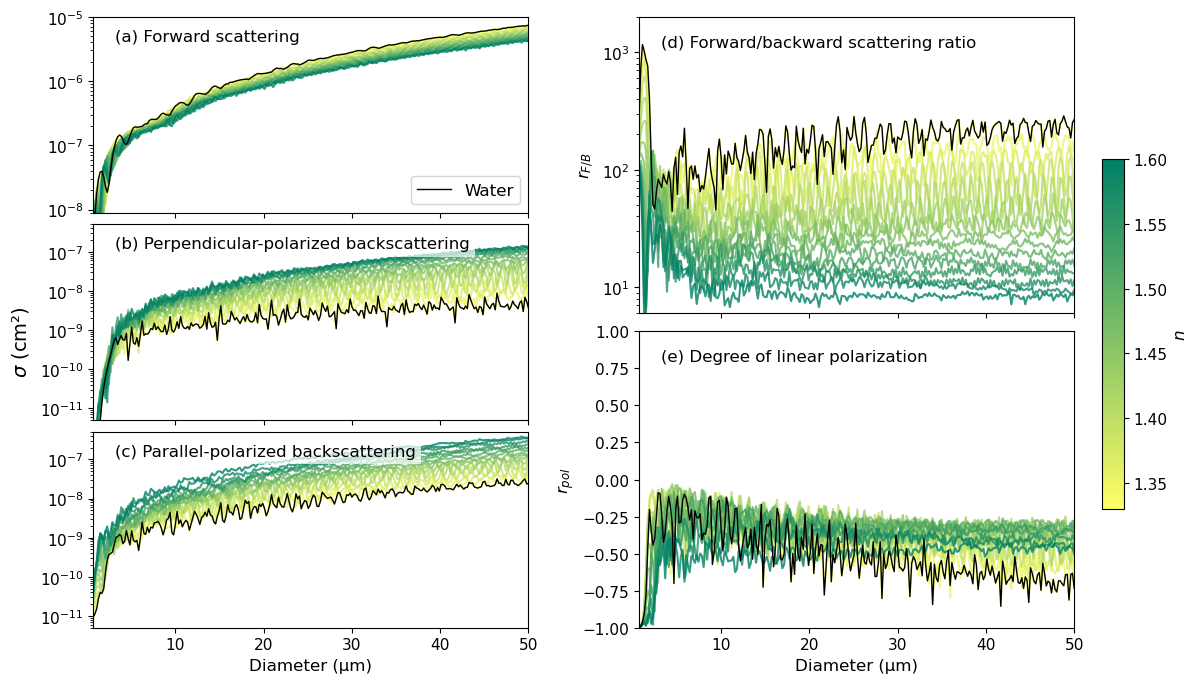

In [50]:
# make stoff a list of r not as values but as words
r =  np.linspace(1.33, 1.6, 15)
stoff = [str(i) for i in r]

# colormap
c = plt.cm.summer_r(np.linspace(0, 1, len(stoff)))

fig = plt.figure(figsize=(12, 7))

# main 2x2 grid
gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1, 1])

# left column: subdivide into 3 rows
gs_left = gs[:, 0].subgridspec(3, 1)
ax1 = fig.add_subplot(gs_left[0, 0])
ax4 = fig.add_subplot(gs_left[1, 0])
ax5 = fig.add_subplot(gs_left[2, 0])

# right column: subdivide into 2 rows
gs_right = gs[:, 1].subgridspec(2, 1)
ax2 = fig.add_subplot(gs_right[0, 0])
ax3 = fig.add_subplot(gs_right[1, 0])

# ----------------- plotting loop -----------------
for i in range(len(stoff)):
    ax1.plot(diam / 1000, Sigma[stoff[i]]['forward'], alpha=0.8, c=c[i])  # forward scattering
    ax2.plot(diam / 1000, Sigma[stoff[i]]['r_fb'], alpha=0.8, c=c[i])  # F/B ratio
    ax3.plot(diam / 1000, Sigma[stoff[i]]['r_pol'], alpha=0.8, c=c[i])  # degree of linear polarization
    ax4.plot(diam / 1000, Sigma[stoff[i]]['S'], alpha=0.8, c=c[i])  # S-pol
    ax5.plot(diam / 1000, Sigma[stoff[i]]['P'], alpha=0.8, c=c[i])  # P-pol

# Water reference curves
ax1.plot(diam/1000, Sigma['1.33']['forward'], label='Water', color='black', lw=1)
ax2.plot(diam/1000, Sigma['1.33']['r_fb'], label='Water', color='black', lw=1)
ax3.plot(diam/1000, Sigma['1.33']['r_pol'], label='Water', color='black', lw=1)
ax4.plot(diam/1000, Sigma['1.33']['S'], label='Water', color='black', lw=1)
ax5.plot(diam/1000, Sigma['1.33']['P'], label='Water', color='black', lw=1)

# scales
for axs in [ax1, ax2, ax4, ax5]:
    axs.set(yscale='log')
# remove xtick labels for upper left column
for ax in (ax1, ax2, ax4):
    ax.tick_params(axis='x', which='both', bottom=True, labelbottom=False)


# labels
# merge the ylabels of ax1, ax4 and ax5
for ax in (ax1, ax4, ax5):
    ax.set_ylabel("")  # clear their individual labels
    ax.set(xlim = (0.5,50))
fig.text(-0.01, 0.5, "$\sigma$ (cm²)", rotation="vertical", va="center", fontsize=14)

ax1.legend(loc='lower right', fontsize=12)
ax2.set_ylabel('$r_{F/B}$', fontsize=12)
ax3.set_ylabel('$r_{pol}$', fontsize=12)
ax3.set_xlabel('Diameter (µm)', fontsize=12)
ax5.set_xlabel('Diameter (µm)', fontsize=12)

ax1.set(ylim = (9*10**-9,10**-5), xlim = (0.7,50))
ax2.set(ylim = (6, 2000), xlim = (0.7,50))
ax3.set(ylim=(-1, 1), xlim = (0.7,50))
ax4.set(ylim = (5*10**-12,5*10**-7), xlim = (0.7,50))
ax5.set(ylim = (5*10**-12,5*10**-7), xlim = (0.7,50))


# colorbar
sm = plt.cm.ScalarMappable(cmap=plt.cm.summer_r, norm=plt.Normalize(vmin=r[0], vmax=r[-1]))
dax = fig.add_axes([0.9, 0.26, 0.018, 0.5])
cbar = plt.colorbar(sm, cax=dax)
cbar.set_label('$n$', fontsize=12)

# panel labels
ax1.text(0.05, 0.94, '(a) Forward scattering', transform=ax1.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax2.text(0.05, 0.94, '(d) Forward/backward scattering ratio', transform=ax2.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax4.text(0.05, 0.94, '(b) Perpendicular-polarized backscattering', transform=ax4.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax5.text(0.05, 0.94, '(c) Parallel-polarized backscattering', transform=ax5.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax3.text(0.05, 0.94, '(e) Degree of linear polarization', transform=ax3.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.tight_layout(rect=[0, 0, 0.9, 1])  # leave space for colorbar
plt.savefig('modeled_scatt_cross.png', dpi=300, bbox_inches='tight')
plt.show()


##### imaginary part

In [44]:
## tryout the new code from Julie
diam = np.linspace(0.7, 50, 250) * 1000  # particle diameter in nm
#water = mie_calculation(diam)

r = 1.33 + 0j + 0.02j * np.linspace(0, 1, 19)
# make stoff a list of r not as values but as words
stoff = [str(i) for i in r]

Sigma_i = {} # make dictionary
for i in range((len(stoff))):
    sigma_fw, sigma_S, sigma_P, sigma_x, sigma_y = mie_calculation(diam, m =r[i])
    r_pol = (sigma_y-sigma_x) / (sigma_y+sigma_x)
    fb = sigma_fw /  (sigma_y+sigma_x)
    sigma = pd.DataFrame([sigma_fw, sigma_x, sigma_y, r_pol, fb], index=['forward', 'P', 'S', 'r_pol', 'r_fb']).T
    Sigma_i[stoff[i]] = sigma


/tmp/ipykernel_2489364/2012436101.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # leave space for colorbar


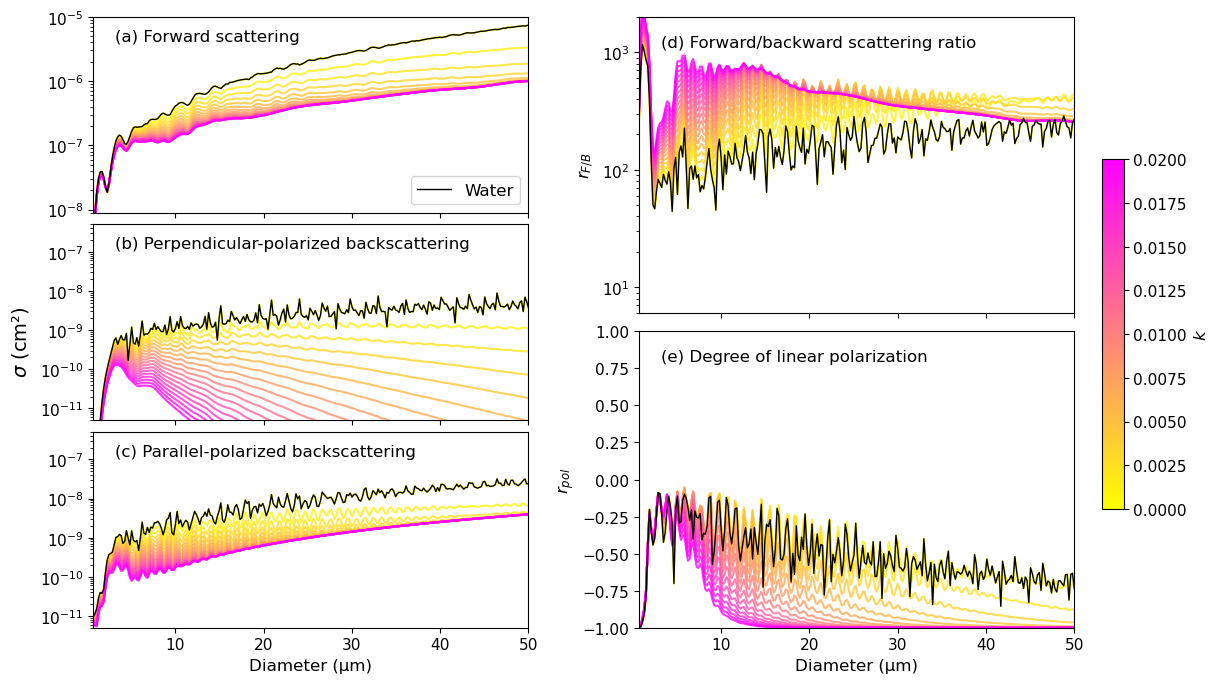

In [49]:
# make stoff a list of r not as values but as words
stoff = [str(i) for i in r]

# colormap
c = plt.cm.spring_r(np.linspace(0, 1, len(stoff)))

fig = plt.figure(figsize=(12, 7))

# main 2x2 grid
gs = gridspec.GridSpec(2, 2, figure=fig, width_ratios=[1, 1])

# left column: subdivide into 3 rows
gs_left = gs[:, 0].subgridspec(3, 1)
ax1 = fig.add_subplot(gs_left[0, 0])
ax4 = fig.add_subplot(gs_left[1, 0])
ax5 = fig.add_subplot(gs_left[2, 0])

# right column: subdivide into 2 rows
gs_right = gs[:, 1].subgridspec(2, 1)
ax2 = fig.add_subplot(gs_right[0, 0])
ax3 = fig.add_subplot(gs_right[1, 0])

# ----------------- plotting loop -----------------
for i in range(len(stoff)):
    ax1.plot(diam / 1000, Sigma_i[stoff[i]]['forward'], alpha=0.8, c=c[i])  # forward scattering
    ax2.plot(diam / 1000, Sigma_i[stoff[i]]['r_fb'], alpha=0.8, c=c[i])  # F/B ratio
    ax3.plot(diam / 1000, Sigma_i[stoff[i]]['r_pol'], alpha=0.8, c=c[i])  # degree of linear polarization
    ax4.plot(diam / 1000, Sigma_i[stoff[i]]['S'], alpha=0.8, c=c[i])  # S-pol
    ax5.plot(diam / 1000, Sigma_i[stoff[i]]['P'], alpha=0.8, c=c[i])  # P-pol

# Water reference curves
ax1.plot(diam/1000, Sigma_i['(1.33+0j)']['forward'], label='Water', color='black', lw=1)
ax2.plot(diam/1000, Sigma_i['(1.33+0j)']['r_fb'], label='Water', color='black', lw=1)
ax3.plot(diam/1000, Sigma_i['(1.33+0j)']['r_pol'], label='Water', color='black', lw=1)
ax4.plot(diam/1000, Sigma_i['(1.33+0j)']['S'], label='Water', color='black', lw=1)
ax5.plot(diam/1000, Sigma_i['(1.33+0j)']['P'], label='Water', color='black', lw=1)


# scales
for axs in [ax1, ax2, ax4, ax5]:
    axs.set(yscale='log')
# remove xtick labels for upper left column
for ax in (ax1, ax2, ax4):
    ax.tick_params(axis='x', which='both', bottom=True, labelbottom=False)


# labels
# merge the ylabels of ax1, ax4 and ax5
for ax in (ax1, ax4, ax5):
    ax.set_ylabel("")  # clear their individual labels
    ax.set(xlim = (0.5,50))
fig.text(-0.01, 0.5, "$\sigma$ (cm²)", rotation="vertical", va="center", fontsize=14)

ax1.legend(loc='lower right', fontsize=12)
ax2.set_ylabel('$r_{F/B}$', fontsize=12)
ax3.set_ylabel('$r_{pol}$', fontsize=12)
ax3.set_xlabel('Diameter (µm)', fontsize=12)
ax5.set_xlabel('Diameter (µm)', fontsize=12)

ax1.set(ylim = (9*10**-9,10**-5), xlim = (0.7,50))
ax2.set(ylim = (6, 2000), xlim = (0.7,50))
ax3.set(ylim=(-1, 1), xlim = (0.7,50))
ax4.set(ylim = (5*10**-12,5*10**-7), xlim = (0.7,50))
ax5.set(ylim = (5*10**-12,5*10**-7), xlim = (0.7,50))


# colorbar
imaginary_part = np.linspace(0, 0.02, 21)
sm = plt.cm.ScalarMappable(cmap=plt.cm.spring_r, norm=plt.Normalize(vmin=imaginary_part[0], vmax=imaginary_part[-1]))
dax = fig.add_axes([0.9, 0.26, 0.018, 0.5])
cbar = plt.colorbar(sm, cax=dax)
cbar.set_label('$k$', fontsize=12)

# panel labels
ax1.text(0.05, 0.94, '(a) Forward scattering', transform=ax1.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax2.text(0.05, 0.94, '(d) Forward/backward scattering ratio', transform=ax2.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax4.text(0.05, 0.94, '(b) Perpendicular-polarized backscattering', transform=ax4.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax5.text(0.05, 0.94, '(c) Parallel-polarized backscattering', transform=ax5.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
ax3.text(0.05, 0.94, '(e) Degree of linear polarization', transform=ax3.transAxes, fontsize=12, va='top', ha='left', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.tight_layout(rect=[0, 0, 0.9, 1])  # leave space for colorbar
plt.savefig('model_scatt_cross_imaginary.png', dpi=300, bbox_inches='tight')
plt.show()
